In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2, beta
from scipy.spatial.distance import mahalanobis
from sklearn.preprocessing import StandardScaler
from IPython.display import display

In [2]:
df = pd.read_excel("ICTIndiv.xlsx", sheet_name="ClusterData")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (37, 21)


,Country,Code,Num,FC_FSMean,FC_Smean,JI_FSMean,JI_Smean,SE_FSMean,SE_Smean,WS_FSMean,...,WO_FSMean,WO_Smean,WH_FSMean,WH_Smean,WE_FSMean,WE_Smean,TI_FSMean,TI_Smean,TA_FSMean,TA_Smean
0,Argentina,1,309,-0.209478,5.508090,-0.207716,5.838188,-0.119341,7.896440,0.368650,...,-0.112377,11.58900,0.199771,10.718450,0.264484,13.83819,-0.313584,9.258900,0.637878,12.96117
1,Bangladesh,3,284,-0.322483,5.267606,0.060421,6.285211,-0.105834,7.841549,-0.424532,...,-0.450292,10.15141,-0.404218,8.718309,-0.137416,11.95423,-0.149924,8.950705,-0.422314,10.11268
2,Brazil,4,348,-0.302804,5.316092,-0.193735,5.896552,-0.351872,7.215517,-0.031595,...,-0.015879,11.93678,0.234890,10.847700,0.210649,13.67529,0.122036,10.339080,0.409593,12.39080
3,Canada,5,311,0.118271,6.064309,0.121863,6.694534,0.056546,8.401929,-0.213239,...,-0.022946,11.91640,-0.035809,10.025720,-0.129374,12.34084,0.074253,10.147910,-0.047191,11.07074
4,China,6,297,0.020991,5.861953,0.300683,7.154882,0.346571,9.178452,-0.529495,...,-0.125905,11.57912,-0.345999,9.084175,0.015262,12.90236,-0.171999,9.582492,-0.096062,10.77778


In [3]:
#understanding structure of the data file provided
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
df.info()

Number of rows: 37
Number of columns: 21

Column names:
['Country', 'Code', 'Num', 'FC_FSMean', 'FC_Smean', 'JI_FSMean', 'JI_Smean', 'SE_FSMean', 'SE_Smean', 'WS_FSMean', 'WS_Smean', 'WO_FSMean', 'WO_Smean', 'WH_FSMean', 'WH_Smean', 'WE_FSMean', 'WE_Smean', 'TI_FSMean', 'TI_Smean', 'TA_FSMean', 'TA_Smean']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37 entries, 0 to 36
Data columns (total 21 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Country    37 non-null     object 
 1   Code       37 non-null     int64  
 2   Num        37 non-null     int64  
 3   FC_FSMean  37 non-null     float64
 4   FC_Smean   37 non-null     float64
 5   JI_FSMean  37 non-null     float64
 6   JI_Smean   37 non-null     float64
 7   SE_FSMean  37 non-null     float64
 8   SE_Smean   37 non-null     float64
 9   WS_FSMean  37 non-null     float64
 10  WS_Smean   37 non-null     float64
 11  WO_FSMean  37 non-null     float64
 12  WO_Smean   

In [4]:
#checking for missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Country      0
Code         0
Num          0
FC_FSMean    0
FC_Smean     0
JI_FSMean    0
JI_Smean     0
SE_FSMean    0
SE_Smean     0
WS_FSMean    0
WS_Smean     0
WO_FSMean    0
WO_Smean     0
WH_FSMean    0
WH_Smean     0
WE_FSMean    0
WE_Smean     0
TI_FSMean    0
TI_Smean     0
TA_FSMean    0
TA_Smean     0
dtype: int64

Total missing values: 0


In [5]:
#remove accidental spaces
df.columns = df.columns.str.strip()

df["Country"] = df["Country"].astype("string").str.strip()

print(df.columns.tolist())
print(df["Country"].head())

['Country', 'Code', 'Num', 'FC_FSMean', 'FC_Smean', 'JI_FSMean', 'JI_Smean', 'SE_FSMean', 'SE_Smean', 'WS_FSMean', 'WS_Smean', 'WO_FSMean', 'WO_Smean', 'WH_FSMean', 'WH_Smean', 'WE_FSMean', 'WE_Smean', 'TI_FSMean', 'TI_Smean', 'TA_FSMean', 'TA_Smean']
0     Argentina
1    Bangladesh
2        Brazil
3        Canada
4         China
Name: Country, dtype: string


In [6]:
#checking for duplicates 
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate country names:",
    df["Country"].duplicated().sum()
)

Duplicate rows: 0
Duplicate country names: 0


In [7]:
attributes = [
    "FC", "JI", "SE", "WS", "WO",
    "WH", "WE", "TI", "TA"
]

FS_columns = [f"{a}_FSMean" for a in attributes]
S_columns = [f"{a}_Smean" for a in attributes]

numeric_columns = ["Code", "Num"] + FS_columns + S_columns

# Confirm that all expected columns exist
missing_columns = [
    col for col in numeric_columns + ["Country"]
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Convert numerical columns, raising an error if invalid text exists
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="raise")

# Check for infinite values
if not np.isfinite(df[numeric_columns].to_numpy()).all():
    raise ValueError("Infinite values found. Investigate them.")

print("All numerical columns validated successfully.")

All numerical columns validated successfully.


In [8]:
score_columns = FS_columns + S_columns

summary = df[score_columns].describe().T

summary["range"] = summary["max"] - summary["min"]

summary = summary[
    ["mean", "std", "min", "25%", "50%", "75%", "max", "range"]
]

display(summary.round(3))

,mean,std,min,25%,50%,75%,max,range
FC_FSMean,-0.008,0.309,-0.497,-0.197,-0.041,0.118,0.697,1.194
JI_FSMean,-0.014,0.275,-0.713,-0.204,-0.046,0.161,0.718,1.431
SE_FSMean,-0.016,0.379,-0.774,-0.250,-0.106,0.144,1.256,2.030
WS_FSMean,0.026,0.345,-0.647,-0.257,0.174,0.290,0.623,1.270
WO_FSMean,-0.004,0.261,-0.450,-0.195,-0.023,0.106,0.604,1.054
WH_FSMean,-0.014,0.276,-0.735,-0.146,-0.029,0.188,0.503,1.238
WE_FSMean,-0.000,0.277,-0.506,-0.256,0.006,0.197,0.633,1.139
TI_FSMean,0.012,0.272,-0.470,-0.185,0.006,0.122,0.709,1.179
TA_FSMean,0.022,0.412,-0.845,-0.224,0.058,0.294,0.668,1.513
FC_Smean,5.826,0.516,5.032,5.508,5.786,6.064,6.981,1.948


In [9]:
#checking for outliers
outliers = []

for col in score_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    flagged = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    for _, row in flagged.iterrows():
        outliers.append({
            "Country": row["Country"],
            "Attribute": col,
            "Observed_Value": row[col],
            "Lower_Bound": lower_bound,
            "Upper_Bound": upper_bound,
            "Flag_Type": (
                "Low" if row[col] < lower_bound else "High"
            )
        })

outlier_df = pd.DataFrame(outliers)

if outlier_df.empty:
    print("No IQR outliers detected.")
else:
    display(
        outlier_df.sort_values(
            ["Attribute", "Observed_Value"]
        ).round(3)
    )

    outlier_df.to_csv("outlier_investigation.csv", index=False)

,Country,Attribute,Observed_Value,Lower_Bound,Upper_Bound,Flag_Type
2,South Korea,FC_FSMean,0.614,-0.671,0.592,High
0,Iran,FC_FSMean,0.681,-0.671,0.592,High
1,Japan,FC_FSMean,0.697,-0.671,0.592,High
9,Iran,FC_Smean,6.961,4.674,6.899,High
10,Japan,FC_Smean,6.981,4.674,6.899,High
3,Iran,JI_FSMean,0.718,-0.753,0.710,High
4,Iran,SE_FSMean,1.256,-0.840,0.734,High
11,Iran,SE_Smean,11.723,5.702,10.332,High
7,India,TI_FSMean,0.664,-0.647,0.583,High
8,Italy,TI_FSMean,0.709,-0.647,0.583,High


In [10]:
if outlier_df.empty:
    print("No country-attribute pairs to summarize.")
    outlier_pairs = pd.DataFrame(
        columns=[
            "Country",
            "Attribute",
            "Number_of_Flags",
            "Flagged_Values"
        ]
    )
else:
    outlier_pairs = outlier_df.copy()

    outlier_pairs["Attribute"] = outlier_pairs["Attribute"].str.replace(
        r"_(FSMean|Smean)$", "", regex=True
    )

    outlier_pairs = (
        outlier_pairs.groupby(["Country", "Attribute"])
        .agg(
            Number_of_Flags=("Observed_Value", "size"),
            Flagged_Values=(
                "Observed_Value",
                lambda x: list(x.round(3))
            )
        )
        .reset_index()
    )

    outlier_pairs = outlier_pairs.sort_values(
        ["Country", "Attribute"]
    )

print("Distinct country-attribute pairs:", len(outlier_pairs))
display(outlier_pairs)

Distinct country-attribute pairs: 11


,Country,Attribute,Number_of_Flags,Flagged_Values
0,India,TI,2,"[0.664, 11.734]"
1,Iran,FC,2,"[0.681, 6.961]"
2,Iran,JI,1,[0.718]
3,Iran,SE,2,"[1.256, 11.723]"
4,Italy,TI,2,"[0.709, 11.903]"
5,Japan,FC,2,"[0.697, 6.981]"
6,Nigeria,WH,1,[7.129]
7,Nigeria,WO,1,[9.172]
8,Pakistan,WH,2,"[-0.735, 7.867]"
9,Poland,WO,2,"[0.604, 14.1]"


In [11]:
def mahalanobis_check(data, columns, score_set, alpha=0.05):
    X = data[columns].astype(float).to_numpy()
    n, p = X.shape

    mean_vector = X.mean(axis=0)
    covariance = np.cov(X, rowvar=False)
    inverse_covariance = np.linalg.pinv(covariance)

    distances_squared = np.array([
        mahalanobis(row, mean_vector, inverse_covariance) ** 2
        for row in X
    ])

    # (1) Large-sample reference: chi-square with p degrees of freedom.
    cutoff_chi2 = chi2.ppf(1 - alpha, df=p)
    # (2) Finite-sample reference: when the mean and covariance are estimated from the same n rows,
    #     d^2 follows (n-1)^2 / n * Beta(p/2, (n-p-1)/2) under multivariate normality.
    #     This is the more appropriate reference for n = 37, p = 9.
    cutoff_beta = (n - 1) ** 2 / n * beta.ppf(1 - alpha, p / 2, (n - p - 1) / 2)

    return pd.DataFrame({
        "Country": data["Country"].values,
        "Score_Set": score_set,
        "Mahalanobis_d2": distances_squared,
        "Cutoff": cutoff_chi2,
        "Flagged_Multivariate": distances_squared > cutoff_chi2,
        "Cutoff_exact_beta": cutoff_beta,
        "Flagged_exact_beta": distances_squared > cutoff_beta
    }).sort_values("Mahalanobis_d2", ascending=False)


FS_mahalanobis = mahalanobis_check(df, FS_columns, "FS")
S_mahalanobis = mahalanobis_check(df, S_columns, "S")

mahalanobis_results = pd.concat(
    [FS_mahalanobis, S_mahalanobis],
    ignore_index=True
)

mahalanobis_results.to_csv(
    "mahalanobis_outlier_check.csv",
    index=False
)

# Show the flagged rows explicitly (a head()/tail() view hides them)
n_tests = len(mahalanobis_results)
print("Flagged with the chi-square cutoff (alpha = 0.05):")
display(
    mahalanobis_results[mahalanobis_results["Flagged_Multivariate"]]
    .drop(columns=["Flagged_Multivariate", "Flagged_exact_beta"]).round(3)
)
print("Flagged with the exact finite-sample (Beta) cutoff (alpha = 0.05):")
display(
    mahalanobis_results[mahalanobis_results["Flagged_exact_beta"]]
    .drop(columns=["Flagged_Multivariate", "Flagged_exact_beta"]).round(3)
)
print(
    f"Tests run: {n_tests}. If the tests were independent and the data clean, about "
    f"{0.05 * n_tests:.1f} flags would be expected by chance at alpha = 0.05 "
    "(FS and S are strongly correlated, so this is only a rough guide)."
)
print("\nFour highest distances in each score set:")
display(mahalanobis_results.groupby("Score_Set").head(4).round(3))

Flagged with the chi-square cutoff (alpha = 0.05):


,Country,Score_Set,Mahalanobis_d2,Cutoff,Cutoff_exact_beta
0,Poland,FS,16.952,16.919,15.012
37,Iran,S,17.826,16.919,15.012
38,Nigeria,S,17.414,16.919,15.012


Flagged with the exact finite-sample (Beta) cutoff (alpha = 0.05):


,Country,Score_Set,Mahalanobis_d2,Cutoff,Cutoff_exact_beta
0,Poland,FS,16.952,16.919,15.012
1,Iran,FS,15.545,16.919,15.012
37,Iran,S,17.826,16.919,15.012
38,Nigeria,S,17.414,16.919,15.012
39,Poland,S,16.630,16.919,15.012


Tests run: 74. If the tests were independent and the data clean, about 3.7 flags would be expected by chance at alpha = 0.05 (FS and S are strongly correlated, so this is only a rough guide).

Four highest distances in each score set:


,Country,Score_Set,Mahalanobis_d2,Cutoff,Flagged_Multivariate,Cutoff_exact_beta,Flagged_exact_beta
0,Poland,FS,16.952,16.919,True,15.012,True
1,Iran,FS,15.545,16.919,False,15.012,True
2,Japan,FS,14.540,16.919,False,15.012,False
3,Ghana,FS,13.712,16.919,False,15.012,False
37,Iran,S,17.826,16.919,True,15.012,True
38,Nigeria,S,17.414,16.919,True,15.012,True
39,Poland,S,16.630,16.919,False,15.012,True
40,South Korea,S,13.872,16.919,False,15.012,False


## Outlier decision

Flagged countries are **retained**. They are genuine countries, not data-entry errors, and with n = 37 removing any of them would weaken the analysis.

* **Univariate (1.5 × IQR rule).** 8 countries are flagged on at least one score column: Iran, Japan, South Korea, India, Italy, Nigeria, Pakistan and Poland (11 distinct country-attribute pairs).
* **Multivariate (Mahalanobis distance, α = 0.05).** With the large-sample χ²(9) cutoff of 16.92, three country-score-set pairs are flagged: Poland (FS, d² = 16.95), Iran (S, d² = 17.83) and Nigeria (S, d² = 17.41). With the exact finite-sample cutoff of 15.01 (appropriate for n = 37, p = 9) the flagged pairs are Iran and Poland (FS) and Iran, Nigeria and Poland (S).
* **Interpretation.** 74 tests were run (37 countries × 2 score sets), so roughly 3.7 flags would be expected by chance at α = 0.05 even for clean data. The FS and S tests are strongly correlated, so this is only a rough guide, but it means the multivariate flags are *indicative*, not grounds for removal. With n = 37 and p = 9 the covariance matrix is also poorly estimated.
* **Sensitivity.** The clustering notebook re-runs K-means leaving out each IQR-flagged country, all eight together, and the multivariate-flagged countries together, for both FS and S scores. The S solution is unchanged when Iran alone is dropped but changes materially when Nigeria is dropped, alone or together with Iran; see that section.

## Note on the exported file
No cleaning was needed (no missing values, duplicates or invalid entries), so `ICT_preprocessed.csv` has the same contents as the raw sheet. Standardisation is done separately for FS and S inside each analysis notebook.

In [12]:
FS_scaler = StandardScaler()
S_scaler = StandardScaler()

X_FS_scaled = pd.DataFrame(
    FS_scaler.fit_transform(df[FS_columns]),
    columns=FS_columns,
    index=df["Country"]
)

X_S_scaled = pd.DataFrame(
    S_scaler.fit_transform(df[S_columns]),
    columns=S_columns,
    index=df["Country"]
)

print("FS dataset shape:", X_FS_scaled.shape)
print("S dataset shape:", X_S_scaled.shape)

print("\nFS standardized data:")
display(X_FS_scaled.head())

print("\nS standardized data:")
display(X_S_scaled.head())

FS dataset shape: (37, 9)
S dataset shape: (37, 9)

FS standardized data:


,FC_FSMean,JI_FSMean,SE_FSMean,WS_FSMean,WO_FSMean,WH_FSMean,WE_FSMean,TI_FSMean,TA_FSMean
Country,,,,,,,,,
Argentina,-0.661152,-0.712284,-0.278032,1.005609,-0.421713,0.785112,0.969265,-1.211817,1.517574
Bangladesh,-1.031388,0.275006,-0.241862,-1.325258,-1.732192,-1.434341,-0.501948,-0.601859,-1.092750
Brazil,-0.966916,-0.660803,-0.900753,-0.170564,-0.047482,0.914162,0.772196,0.411732,0.955509
Canada,0.412645,0.501242,0.192992,-0.704348,-0.074886,-0.080563,-0.472509,0.233646,-0.169150
China,0.093928,1.159662,0.969677,-1.633706,-0.474178,-1.220408,0.056953,-0.684131,-0.289476



S standardized data:


,FC_Smean,JI_Smean,SE_Smean,WS_Smean,WO_Smean,WH_Smean,WE_Smean,TI_Smean,TA_Smean
Country,,,,,,,,,
Argentina,-0.623496,-0.665786,-0.213426,0.498650,-0.318850,0.776305,0.931628,-0.903108,1.655227
Bangladesh,-1.095688,-0.009872,-0.265138,-1.249582,-1.785592,-1.422927,-0.692318,-1.297345,-1.068499
Brazil,-1.000486,-0.580149,-0.854916,-0.696623,0.035982,0.918420,0.791211,0.478635,1.109839
Canada,0.468643,0.590726,0.262789,-0.516000,0.015189,0.014622,-0.359066,0.234095,-0.152402
China,0.071316,1.266192,0.994343,-1.282482,-0.328931,-1.020643,0.124956,-0.489176,-0.432530


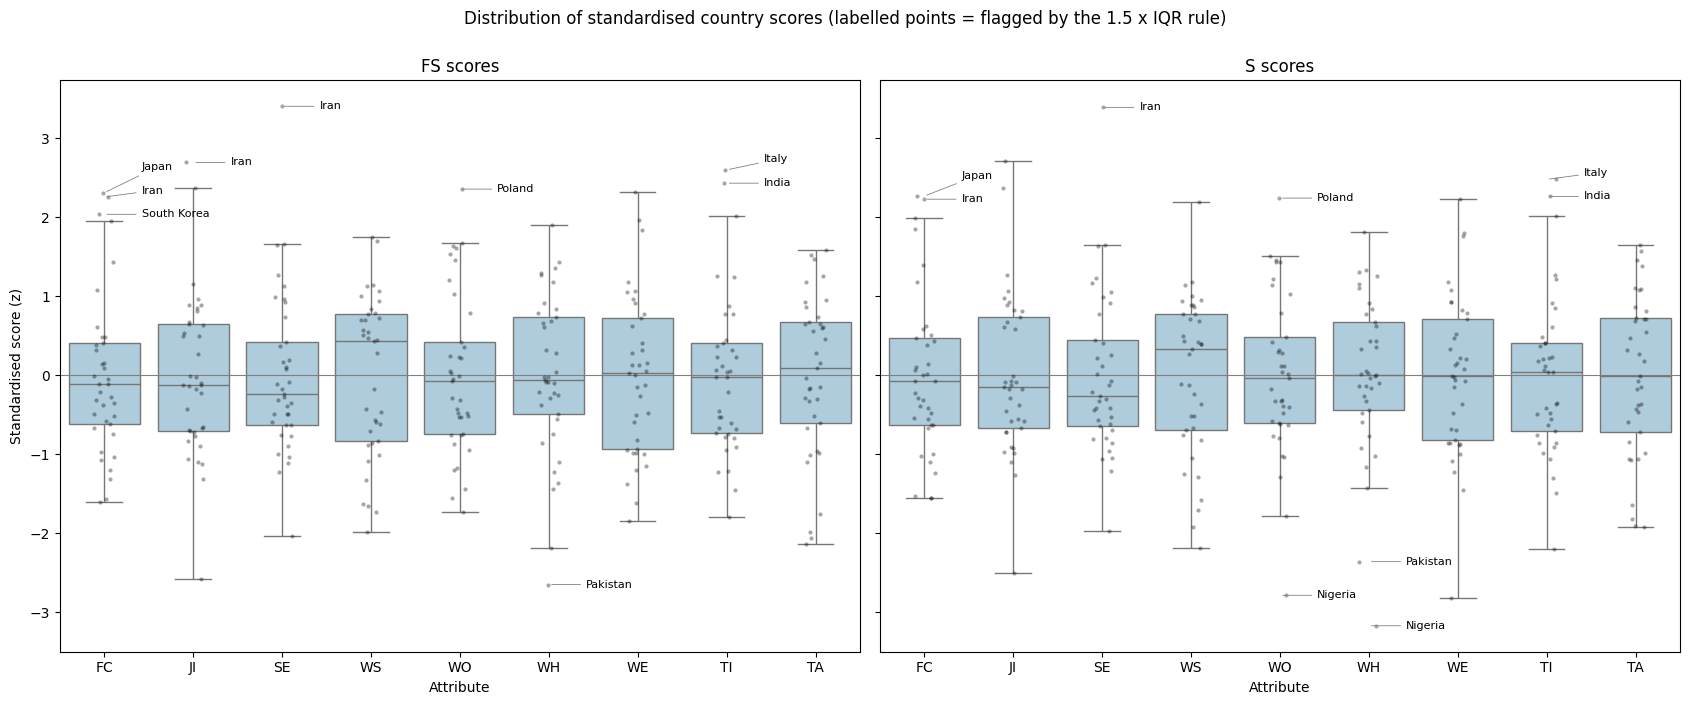

In [13]:
# Boxplots of the standardised scores. Points flagged by the 1.5 x IQR rule in the outlier cell above are labelled.
X_standardized = pd.concat([X_FS_scaled, X_S_scaled], axis=1)

# Standardisation is an affine transformation, so the IQR rule flags exactly the same
# observations on the standardised scale as on the raw scale. Check this explicitly.
z_flag_count = 0
for col in score_columns:
    q1, q3 = X_standardized[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    z_flag_count += int(((X_standardized[col] < q1 - 1.5 * iqr) | (X_standardized[col] > q3 + 1.5 * iqr)).sum())
assert z_flag_count == len(outlier_df), (z_flag_count, len(outlier_df))

plot_long = (
    X_standardized
    .rename_axis("Country")
    .reset_index()
    .melt(id_vars="Country", var_name="Score_Column", value_name="Standardized_Score")
)


def spread_labels(ys, gap=0.30):
    """Return label heights that are at least `gap` apart (keeps neighbouring labels legible)."""
    order = np.argsort(ys)
    out = np.array(ys, dtype=float)
    for a, b in zip(order[:-1], order[1:]):
        out[b] = max(out[b], out[a] + gap)
    return out


fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharey=True)

for ax, (cols, title) in zip(axes, [(FS_columns, "FS scores"), (S_columns, "S scores")]):
    sub = plot_long[plot_long["Score_Column"].isin(cols)]
    sns.boxplot(data=sub, x="Score_Column", y="Standardized_Score", order=cols,
                showfliers=False, color="#a6cee3", ax=ax)
    sns.stripplot(data=sub, x="Score_Column", y="Standardized_Score", order=cols,
                  color="black", alpha=0.35, size=3, jitter=0.12, ax=ax)

    for xpos, col in enumerate(cols):
        flagged_here = outlier_df[outlier_df["Attribute"] == col] if not outlier_df.empty else outlier_df
        if flagged_here.empty:
            continue
        names = flagged_here["Country"].tolist()
        z = np.array([X_standardized.loc[c, col] for c in names])
        label_y = spread_labels(z)
        for name, zi, yi in zip(names, z, label_y):
            ax.annotate(name, xy=(xpos, zi), xytext=(xpos + 0.42, yi), fontsize=8, va="center",
                        arrowprops=dict(arrowstyle="-", color="grey", lw=0.6))

    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Attribute")
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels([c.split("_")[0] for c in cols])

axes[0].set_ylabel("Standardised score (z)")
axes[1].set_ylabel("")
fig.suptitle("Distribution of standardised country scores (labelled points = flagged by the 1.5 x IQR rule)", y=1.0)
plt.tight_layout()
plt.savefig("standardized_score_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
FS_summary = df[FS_columns].describe().T
S_summary = df[S_columns].describe().T

print("FS SCORE SET")
display(
    FS_summary[["mean", "std", "min", "max"]].round(3)
)

print("S SCORE SET")
display(
    S_summary[["mean", "std", "min", "max"]].round(3)
)

FS SCORE SET


,mean,std,min,max
FC_FSMean,-0.008,0.309,-0.497,0.697
JI_FSMean,-0.014,0.275,-0.713,0.718
SE_FSMean,-0.016,0.379,-0.774,1.256
WS_FSMean,0.026,0.345,-0.647,0.623
WO_FSMean,-0.004,0.261,-0.450,0.604
WH_FSMean,-0.014,0.276,-0.735,0.503
WE_FSMean,-0.000,0.277,-0.506,0.633
TI_FSMean,0.012,0.272,-0.470,0.709
TA_FSMean,0.022,0.412,-0.845,0.668


S SCORE SET


,mean,std,min,max
FC_Smean,5.826,0.516,5.032,6.981
JI_Smean,6.292,0.691,4.589,8.140
SE_Smean,8.123,1.076,6.037,11.723
WS_Smean,13.432,1.076,11.108,15.766
WO_Smean,11.902,0.994,9.172,14.100
WH_Smean,10.012,0.922,7.129,11.660
WE_Smean,12.757,1.176,9.484,15.352
TI_Smean,9.965,0.793,8.247,11.903
TA_Smean,11.230,1.060,9.224,12.961


In [15]:
# Validate the final dataset before export
score_columns = FS_columns + S_columns
numeric_columns = ["Code", "Num"] + score_columns

assert df.shape == (37, 21), (
    f"Unexpected dataset shape: {df.shape}"
)

assert df[score_columns].notna().all().all(), (
    "Missing score values found."
)

assert np.isfinite(df[numeric_columns].to_numpy(dtype=float)).all(), "Infinite or invalid numeric values found."

print("Final dataset shape:", df.shape)
print("Missing score values:", df[score_columns].isna().sum().sum())
print("All score values are finite.")
print("Ready to export.")

Final dataset shape: (37, 21)
Missing score values: 0
All score values are finite.
Ready to export.


In [16]:
df.to_csv("ICT_preprocessed.csv", index=False)

print("Final preprocessed dataset saved")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Final preprocessed dataset saved
Rows: 37
Columns: 21
